# Detections of objects labelled in only one modality, 2026-10-30

The two `video_*_test` splits are the same 3,749 time-synced frame pairs, but each modality's annotators label what
their own camera shows (`test_set_quality.ipynb` §2c): IR has 0.25× the bikes, 0.33× the signs and 0.38× the lights of
RGB, and at night IR labels cars that RGB cannot see (Roadmap R10). **The question here: are the frozen heads of F15
(`det_rgb`, `det_ir`) charged with false positives for objects that the other modality labels but this one does not?**
If so, part of the 2×2 gap of `detector_transfer_results.ipynb` would be a labelling artefact.

Three checks, all re-scored from the 4 saved F15 detection files (no inference):
1. **Precision per class against the label ratio** (classes ordered from the most to the least asymmetric).
2. **Every false positive mapped into the paired frame** with the registration of `test_set_quality.ipynb` §2b, and
   typed: is it an object the other modality labelled?
   2.1. The reverse: are the objects labelled in only one modality detected in the other image?
3. **The 2×2 re-scored** with the other modality's extra labels as ignore regions.

**Headline** (preliminary: no CIs until F6; operating point score ≥ 0.3, IoU 0.5):
- **No: the label asymmetry barely costs the heads anything.** At most 14 % of a cell's false positives of a class sit
  on an object only the other modality labelled, and not counting them raises precision by at most 0.04 (§2). Treating
  every such object as an ignore region changes AP by ≤ 0.003 and AP50 by ≤ 0.006, and leaves F15's transfer ratios
  unchanged (0.615 → 0.612, 0.569 → 0.569; §3).
- **Why: the detectors agree with each modality's annotator about what is visible.** Of the signs and lights only RGB
  labels, `det_rgb` finds 31 % and 52 % in the RGB image but 2 % in the IR image, and `det_ir` likewise finds 2–6 % in
  IR (§2.1). The IR annotators skipped objects that do not show in thermal, and the heads do not fire there either.
  The same holds the other way for the night cars only IR labels.
- **Precision does not follow the label ratio** (§1). The sparse modality's precision is lower only for `det_rgb` on
  IR signs (0.55 → 0.14), and those false positives are 77 % background, not unlabelled signs. For lights, IR test (the
  sparse one) has the higher precision with both heads.
- **For R10:** the sign/light/bike asymmetry is a difference in what each modality *shows*, and the GT follows it. A
  cross-modal per-class AP is therefore not inflated or deflated by missing labels in any measurable way; it is low
  because those objects are hard or invisible in the other modality. Person + car stays the cleaner comparison, but
  for sample size and scene mix, not for labelling.

In [1]:
import contextlib
import copy
import hashlib
import io
import json
import math
from collections import Counter, defaultdict
from multiprocessing import get_context
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display
from matplotlib.patches import Patch
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
from scipy.optimize import linear_sum_assignment

from irwm.data.classes import CATEGORY_ID_TO_LABEL, CLASS_NAMES, LABEL_TO_CATEGORY_ID, normalised_area
from irwm.data.flir import FlirSplit, load_rgb_thermal_map, split_dir
from irwm.detection.inference import load_detections
from irwm.utils.paths import load_env, output_root

load_env()  # FLIR data root for FlirSplit
# Run dir and detections copied from the cluster into <repo>/outputs; falls back to $IRWM_OUTPUT_ROOT.
from irwm.utils.paths import repo_root
OUT = repo_root() / "outputs"
if not (OUT / "detection/detections").is_dir():
    OUT = output_root()

RUN_DIR = OUT / "detection/2026-10-28/13-49-32"  # F15: SLURM 5526475, W&B j3apbc75
TRANSFER = json.loads((RUN_DIR / "transfer.json").read_text())
HEADS = ["det_rgb", "det_ir"]
MODS = ["rgb", "thermal"]
OTHER = {"rgb": "thermal", "thermal": "rgb"}
HEAD_MOD = {"det_rgb": "rgb", "det_ir": "thermal"}  # modality each head was trained on
CELLS = [(h, m) for h in HEADS for m in MODS]

for h, m in CELLS:
    d = TRANSFER["detections"][h][m]
    assert hashlib.sha256((OUT / d["path"]).read_bytes()).hexdigest() == d["sha256"], (h, m)
DETS = {(h, m): load_detections(OUT / TRANSFER["detections"][h][m]["path"])["detections"] for h, m in CELLS}
SPLIT = {m: FlirSplit.load(m, "test") for m in MODS}
GT_OWN = {m: SPLIT[m].to_coco_gt("normalised") for m in MODS}  # as F8's coco_map / F15 score it
print(f"transfer.json at {TRANSFER['git']['commit'][:7]}; 4 detection files match their SHA-256, "
      f"{sum(map(len, DETS.values())):,} detections")

/home/leonardo.ulloa/projects/ir-world-model/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/leonardo.ulloa/projects/ir-world-model/.venv/lib/python3.11/site-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)


/home/leonardo.ulloa/projects/ir-world-model/third_party/detrex/detrex/config/config.py:18: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


transfer.json at 1179143; 4 detection files match their SHA-256, 4,498,800 detections


In [2]:
# Plot style, as in detector_transfer_results.ipynb: hue = the head's training modality (RGB blue, thermal orange);
# solid = in-domain cell, hatched = cross-modal cell.
MOD_COLOR = {"rgb": "#2a78d6", "thermal": "#eb6834"}
MOD_LABEL = {"rgb": "RGB", "thermal": "IR"}
INK, MUTED, GRID, REF = "#0b0b0b", "#52514e", "#e6e5e0", "#a8a7a2"
RATIO_FILL = "#f0efec"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#8a8984", "axes.labelcolor": MUTED, "xtick.color": MUTED,
    "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.axisbelow": True, "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold",
    "legend.frameon": False, "hatch.linewidth": 0.8,
})


def cell_label(h, m):
    return f"{h} → {MOD_LABEL[m]} test"


def cell_style(h, m):
    c = MOD_COLOR[HEAD_MOD[h]]
    if HEAD_MOD[h] == m:
        return dict(facecolor=c, edgecolor=c, linewidth=1.0)
    return dict(facecolor="white", edgecolor=c, hatch="////", linewidth=1.0)


def table(header, rows):
    fmt = lambda v: f"{v:.3f}" if isinstance(v, float) else ("–" if v is None else str(v))  # noqa: E731
    lines = ["| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
    lines += ["| " + " | ".join(fmt(v) for v in r) + " |" for r in rows]
    display(Markdown("\n".join(lines)))

## 0. Registration and cross-modal GT status

Copied from `test_set_quality.ipynb` §2b–2c (notebooks never import each other; kept in sync by hand). Per video pair, a
square-pixel similarity maps thermal to RGB coordinates (normalised by frame size), fitted on matched person/car
boxes; its median residual is 2–8 RGB px. Every kept GT box then gets a status against the other modality's GT:
`matched` (same class, IoU ≥ 0.3 after growing both boxes by 1 % of the frame), `class swap`, `border` (cut by the
edge of the shared view), `missing` (inside the shared view, no counterpart) or `empty frame`.

Here the status is used in one direction: a GT box that is `missing` or on an `empty frame` is an object **only this
modality labelled**, and its mapped box in the other frame is where the other modality's detector may fire with no GT
to match.

In [3]:
INDEX = {m: json.loads((split_dir(m, "test") / "index.json").read_text()) for m in MODS}
VIDEO_META = {m: {v["id"]: v for v in INDEX[m]["videos"]} for m in MODS}
BY_NAME = {m: {r.file_name.removeprefix("data/"): r for r in SPLIT[m]} for m in MODS}
PAIRS = sorted(((BY_NAME["rgb"][a], BY_NAME["thermal"][b]) for a, b in load_rgb_thermal_map().items()),
               key=lambda p: (p[0].video_id, p[0].frame_index))


def prefix(m, video_id):
    """Recording id shared by the two files of a pair, e.g. '1636345164' from '1636345164_visible.zip'."""
    return VIDEO_META[m][video_id]["filename"].split("_")[0]


PAIR_FRAMES = defaultdict(list)  # prefix -> [(rgb record, thermal record)] in frame order
for r, t in PAIRS:
    PAIR_FRAMES[prefix("rgb", r.video_id)].append((r, t))
ORDER = sorted(PAIR_FRAMES, key=lambda p: -len(PAIR_FRAMES[p]))


# --- test_set_quality.ipynb §2b, unchanged ---
def ncent(boxes, x):
    """COCO xywh in px -> [N, 4] (cx, cy, w, h) normalised by the frame size of record x."""
    b = np.asarray(boxes, dtype=float).reshape(-1, 4)
    s = np.array([x.width, x.height] * 2, dtype=float)
    return np.c_[b[:, :2] + b[:, 2:] / 2, b[:, 2:]] / s


def to_rgb(P, c):
    """Thermal (cx, cy, w, h) normalised -> RGB normalised, with P = (a_x, b_x, a_y, b_y)."""
    return np.c_[P[0] * c[:, 0] + P[1], P[2] * c[:, 1] + P[3], P[0] * c[:, 2], P[2] * c[:, 3]]


FIT_CLASSES = (CLASS_NAMES.index("person"), CLASS_NAMES.index("car"))


def aspect_k(r, t):
    """a_y / a_x of a square-pixel similarity between thermal frame t and RGB frame r."""
    return (t.height / r.height) / (t.width / r.width)


def lstsq_map(X, Y, k=None):
    """Least-squares P = (a_x, b_x, a_y, b_y) from matched centres X (IR) -> Y (RGB); a_y = k · a_x unless k is None."""
    if k is None:  # free fit, one line per axis
        (ax_, bx), (ay, by) = np.polyfit(X[:, 0], Y[:, 0], 1), np.polyfit(X[:, 1], Y[:, 1], 1)
        return np.array([ax_, bx, ay, by])
    A = np.zeros((2 * len(X), 3))
    A[0::2, 0], A[0::2, 1], A[1::2, 0], A[1::2, 2] = X[:, 0], 1, k * X[:, 1], 1
    a, bx, by = np.linalg.lstsq(A, Y[:, :2].ravel(), rcond=None)[0]
    return np.array([a, bx, k * a, by])


def fit_mapping(pairs, P0=None, gates=(0.2, 0.1, 0.05, 0.03), free=False):
    """Fit P on frame pairs [(rgb, thermal)] of one video pair.

    Returns (P, n matched boxes, median residual in RGB-normalised units, (y min, y max) of the matched IR centres).
    """
    P = np.array([1.0, 0.0, 1.0, 0.0]) if P0 is None else np.asarray(P0, dtype=float)
    k = None if free else aspect_k(*pairs[0])
    res = np.array([np.nan])
    for gate in gates:
        X, Y = [], []
        for r, t in pairs:
            cr, ct = ncent(r.boxes, r), to_rgb(P, ncent(t.boxes, t))
            for c in FIT_CLASSES:
                i, j = np.flatnonzero(r.labels == c), np.flatnonzero(t.labels == c)
                if not len(i) or not len(j):
                    continue
                d = np.linalg.norm(cr[i, None, :2] - ct[None, j, :2], axis=-1)
                a, b = linear_sum_assignment(d)
                ok = d[a, b] < gate
                X.append(ncent(t.boxes, t)[j[b[ok]]])
                Y.append(cr[i[a[ok]]])
        X, Y = np.concatenate(X or [np.zeros((0, 4))]), np.concatenate(Y or [np.zeros((0, 4))])
        if len(X) < 10:
            return P, len(X), np.nan, (np.nan, np.nan)
        for _ in range(3):  # trimmed least squares: drop residuals > 3x the median, refit
            P = lstsq_map(X, Y, k)
            res = np.linalg.norm(to_rgb(P, X)[:, :2] - Y[:, :2], axis=1)
            keep = res <= 3 * np.median(res)
            X, Y = X[keep], Y[keep]
    return P, len(X), float(np.median(res)), (float(X[:, 1].min()), float(X[:, 1].max()))


# --- test_set_quality.ipynb §2c, unchanged ---
IOU_MATCH, BOX_PAD, BORDER = 0.3, 0.01, 0.02


def n_boxes(x):
    return len(x.labels) + len(x.ignore_boxes)


def xyxy(c):
    return np.c_[c[:, :2] - c[:, 2:] / 2, c[:, :2] + c[:, 2:] / 2]


def iou(a, b):
    """[N, 4] x [M, 4] xyxy -> [N, M]."""
    if not len(a) or not len(b):
        return np.zeros((len(a), len(b)))
    lt = np.maximum(a[:, None, :2], b[None, :, :2])
    rb = np.minimum(a[:, None, 2:], b[None, :, 2:])
    inter = np.prod(np.clip(rb - lt, 0, None), axis=-1)
    area = lambda x: np.prod(x[:, 2:] - x[:, :2], axis=-1)  # noqa: E731
    return inter / (area(a)[:, None] + area(b)[None] - inter)


def shared_view(P):
    """IR view ∩ RGB frame in RGB-normalised xyxy."""
    return np.r_[np.maximum([P[1], P[3]], 0), np.minimum([P[0] + P[1], P[2] + P[3]], 1)]


def compare_pair(r, t, P, iou_match=IOU_MATCH, pad=BOX_PAD):
    """Status of every kept box of r (rgb) and t (thermal): (array[str] for r.boxes, array[str] for t.boxes).

    Overlaps are IoUs of boxes in RGB-normalised coordinates, each grown by `pad` on every side.
    """
    grow = np.array([-pad, -pad, pad, pad])
    br, bt = xyxy(ncent(r.boxes, r)) + grow, xyxy(to_rgb(P, ncent(t.boxes, t))) + grow
    gr, gt = xyxy(ncent(r.ignore_boxes, r)) + grow, xyxy(to_rgb(P, ncent(t.ignore_boxes, t))) + grow
    st = {"rgb": np.full(len(br), "missing", dtype=object), "thermal": np.full(len(bt), "missing", dtype=object)}
    if n_boxes(t) == 0 or n_boxes(r) == 0:
        st["rgb" if n_boxes(t) == 0 else "thermal"][:] = "empty frame"
        return st["rgb"], st["thermal"]
    for c in range(len(CLASS_NAMES)):
        i, j = np.flatnonzero(r.labels == c), np.flatnonzero(t.labels == c)
        m = iou(br[i], bt[j])
        if m.size:
            a, b = linear_sum_assignment(-m)
            k = m[a, b] >= iou_match
            st["rgb"][i[a[k]]] = "matched"
            st["thermal"][j[b[k]]] = "matched"
    ur, ut = st["rgb"] == "missing", st["thermal"] == "missing"
    cross = iou(br, bt) * (r.labels[:, None] != t.labels[None, :]) * ur[:, None] * ut[None, :]
    swap_r = (cross.max(1, initial=0) >= iou_match) | (iou(br, gt).max(1, initial=0) >= iou_match)
    swap_t = (cross.max(0, initial=0) >= iou_match) | (iou(bt, gr).max(1, initial=0) >= iou_match)
    st["rgb"][ur & swap_r] = "class swap"
    st["thermal"][ut & swap_t] = "class swap"
    shared = shared_view(P)
    for m, b in [("rgb", br - grow), ("thermal", bt - grow)]:
        out = (b[:, :2] < shared[:2] + BORDER).any(1) | (b[:, 2:] > shared[2:] - BORDER).any(1)
        st[m][(st[m] == "missing") & out] = "border"
    return st["rgb"], st["thermal"]
# --- end of the copy ---


MAP = {p: fit_mapping(PAIR_FRAMES[p])[0] for p in ORDER}
FRAME = {}  # (modality, image_id) -> (rgb record, thermal record, P)
STATUS = {}  # (modality, image_id) -> status of each kept box against the other modality
for p in ORDER:
    for r, t in PAIR_FRAMES[p]:
        FRAME["rgb", r.image_id] = FRAME["thermal", t.image_id] = (r, t, MAP[p])
        STATUS["rgb", r.image_id], STATUS["thermal", t.image_id] = compare_pair(r, t, MAP[p])

ONLY_HERE = ("missing", "empty frame")  # labelled in this modality, no counterpart in the other
rows = []
for c, name in enumerate(CLASS_NAMES):
    row = [name]
    for m in MODS:
        n = sum(len(x.labels[x.labels == c]) for x in SPLIT[m])
        k = sum(int(np.isin(STATUS[m, x.image_id][x.labels == c], ONLY_HERE).sum()) for x in SPLIT[m])
        row += [n, f"{k:,} ({k / n:.0%})"]
    rows.append(row)
table(["class", "RGB GT", "RGB only (no IR box)", "IR GT", "IR only (no RGB box)"], rows)

| class | RGB GT | RGB only (no IR box) | IR GT | IR only (no RGB box) |
|---|---|---|---|---|
| person | 11278 | 581 (5%) | 12323 | 1,626 (13%) |
| bike | 446 | 297 (67%) | 113 | 2 (2%) |
| car | 30893 | 3,185 (10%) | 30517 | 3,378 (11%) |
| motor | 3573 | 333 (9%) | 3314 | 137 (4%) |
| light | 17818 | 10,739 (60%) | 6758 | 220 (3%) |
| sign | 17213 | 11,488 (67%) | 5660 | 1,020 (18%) |

## 1. Precision per class vs label ratio

**Label ratio** of a class = GT boxes in the modality that labels it less ÷ GT boxes in the modality that labels it
more, on the full test splits (the two splits are the same 3,749 time-synced frame pairs). The classes are ordered from
the lowest ratio to the highest. If one modality's annotators skip a class that the other labels, a detector that finds
those objects is charged with false positives in the sparse modality, so precision should drop there for the classes
on the left.

**Precision** = TP ÷ (TP + FP) over the detections with score ≥ `TAU`, matched as `COCOeval` does at IoU 0.5 (greedy by
score, one GT per detection, top 100 per image and class). A detection on an ignore region (truck, bus, …) is neither.
`TAU = 0.3` is a fixed operating point; the table after the figure gives 0.2 and 0.5 too, because the heads are not
calibrated alike.

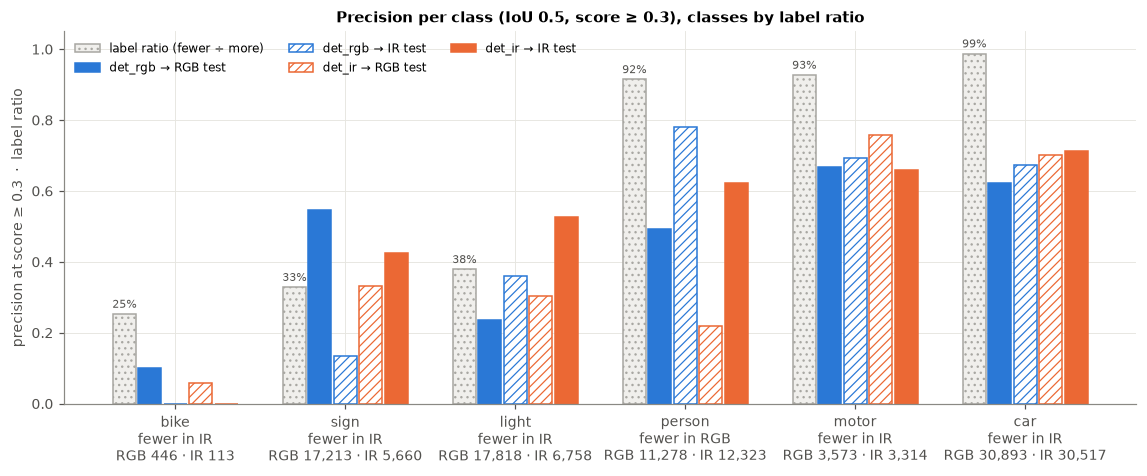

| class | label ratio | cell | P @ 0.2 | P @ 0.3 | P @ 0.5 | TP / FP @ 0.3 | recall @ 0.3 |
|---|---|---|---|---|---|---|---|
| bike | 0.25 | det_rgb → RGB test | 0.061 | 0.101 | 0.333 | 16 / 142 | 0.036 |
| bike | 0.25 | det_rgb → IR test | 0.000 | 0.000 | 0.000 | 0 / 77 | 0.000 |
| bike | 0.25 | det_ir → RGB test | 0.042 | 0.058 | 0.043 | 19 / 306 | 0.043 |
| bike | 0.25 | det_ir → IR test | 0.000 | 0.000 | 0.000 | 0 / 172 | 0.000 |
| sign | 0.33 | det_rgb → RGB test | 0.329 | 0.546 | 0.853 | 4,693 / 3,908 | 0.273 |
| sign | 0.33 | det_rgb → IR test | 0.114 | 0.135 | 0.198 | 414 / 2,647 | 0.073 |
| sign | 0.33 | det_ir → RGB test | 0.245 | 0.333 | 0.472 | 2,032 / 4,063 | 0.118 |
| sign | 0.33 | det_ir → IR test | 0.329 | 0.424 | 0.586 | 916 / 1,242 | 0.162 |
| light | 0.38 | det_rgb → RGB test | 0.123 | 0.235 | 0.482 | 3,551 / 11,546 | 0.199 |
| light | 0.38 | det_rgb → IR test | 0.246 | 0.361 | 0.606 | 778 / 1,380 | 0.115 |
| light | 0.38 | det_ir → RGB test | 0.232 | 0.303 | 0.411 | 2,472 / 5,699 | 0.139 |
| light | 0.38 | det_ir → IR test | 0.418 | 0.525 | 0.687 | 1,367 / 1,235 | 0.202 |
| person | 0.92 | det_rgb → RGB test | 0.267 | 0.492 | 0.826 | 5,480 / 5,668 | 0.486 |
| person | 0.92 | det_rgb → IR test | 0.576 | 0.780 | 0.936 | 4,054 / 1,143 | 0.329 |
| person | 0.92 | det_ir → RGB test | 0.154 | 0.219 | 0.406 | 2,519 / 9,003 | 0.223 |
| person | 0.92 | det_ir → IR test | 0.506 | 0.623 | 0.789 | 8,600 / 5,215 | 0.698 |
| motor | 0.93 | det_rgb → RGB test | 0.461 | 0.668 | 0.922 | 1,459 / 725 | 0.408 |
| motor | 0.93 | det_rgb → IR test | 0.582 | 0.693 | 0.825 | 181 / 80 | 0.055 |
| motor | 0.93 | det_ir → RGB test | 0.622 | 0.757 | 0.896 | 1,238 / 397 | 0.346 |
| motor | 0.93 | det_ir → IR test | 0.571 | 0.658 | 0.763 | 449 / 233 | 0.135 |
| car | 0.99 | det_rgb → RGB test | 0.424 | 0.623 | 0.868 | 17,764 / 10,762 | 0.575 |
| car | 0.99 | det_rgb → IR test | 0.514 | 0.673 | 0.876 | 15,571 / 7,557 | 0.510 |
| car | 0.99 | det_ir → RGB test | 0.589 | 0.702 | 0.857 | 12,186 / 5,177 | 0.394 |
| car | 0.99 | det_ir → IR test | 0.612 | 0.714 | 0.826 | 21,646 / 8,663 | 0.709 |

In [4]:
TAU, TAUS = 0.3, (0.2, 0.3, 0.5)
CAT_IDS = [LABEL_TO_CATEGORY_ID[k] for k in range(len(CLASS_NAMES))]
N_GT = {m: Counter(CLASS_NAMES[int(l)] for x in SPLIT[m] for l in x.labels) for m in MODS}
RATIO = {c: min(N_GT["rgb"][c], N_GT["thermal"][c]) / max(N_GT["rgb"][c], N_GT["thermal"][c]) for c in CLASS_NAMES}
SPARSE = {c: min(MODS, key=lambda m: N_GT[m][c]) for c in CLASS_NAMES}  # the modality that labels c less
BY_RATIO = sorted(CLASS_NAMES, key=RATIO.get)


def match_at_50(gt, dets, score_min=min(TAUS)):
    """COCOeval matching at IoU 0.5, area "all", maxDets 100, on detections with score ≥ score_min.

    Returns one array per field over the evaluated detections: image_id, label, score, bbox (xywh px), status
    ("TP" / "FP" / "ign"), plus the number of non-crowd GT boxes per label. Filtering by score first gives the
    same matches for every detection above score_min, because COCOeval matches greedily in score order.
    """
    dets = [d for d in dets if d["score"] >= score_min]
    with contextlib.redirect_stdout(io.StringIO()):
        coco_gt = COCO()
        coco_gt.dataset = copy.deepcopy(gt)
        coco_gt.createIndex()
        coco_dt = coco_gt.loadRes(copy.deepcopy(dets))
        E = COCOeval(coco_gt, coco_dt, iouType="bbox")
        E.params.iouThrs = np.array([0.5])
        E.params.areaRng, E.params.areaRngLbl, E.params.maxDets = [[0, 1e10]], ["all"], [100]
        E.evaluate()
    out = defaultdict(list)
    for e in E.evalImgs:
        if e is None:
            continue
        for did, mt, ig in zip(e["dtIds"], e["dtMatches"][0], e["dtIgnore"][0]):
            d = coco_dt.anns[did]
            out["image_id"].append(d["image_id"])
            out["label"].append(CATEGORY_ID_TO_LABEL[d["category_id"]])
            out["score"].append(d["score"])
            out["bbox"].append(d["bbox"])
            out["status"].append("ign" if ig else ("TP" if mt else "FP"))
    out = {k: np.array(v) for k, v in out.items()}
    n_gt = Counter(CATEGORY_ID_TO_LABEL[a["category_id"]] for a in gt["annotations"] if not a["iscrowd"])
    return out, n_gt


MATCH = {(h, m): match_at_50(GT_OWN[m], DETS[h, m]) for h, m in CELLS}


def prec_rec(mt, n_gt, c, tau=TAU, drop=None):
    """Precision and recall of class c at score ≥ tau; `drop` = boolean mask of FPs not to count."""
    k = (mt["label"] == CLASS_NAMES.index(c)) & (mt["score"] >= tau)
    tp = int((k & (mt["status"] == "TP")).sum())
    fp_mask = k & (mt["status"] == "FP")
    if drop is not None:
        fp_mask &= ~drop
    fp = int(fp_mask.sum())
    return (tp / (tp + fp) if tp + fp else math.nan), tp / n_gt[CLASS_NAMES.index(c)], tp, fp


def precision_plot(drop=None, title=""):
    fig, ax = plt.subplots(figsize=(10.5, 4.4))
    x = np.arange(len(BY_RATIO))
    w = 0.15
    slots = [None, *CELLS]
    for i, slot in enumerate(slots):
        off = (i - (len(slots) - 1) / 2) * w
        if slot is None:
            v = [RATIO[c] for c in BY_RATIO]
            ax.bar(x + off, v, w * 0.9, facecolor=RATIO_FILL, edgecolor=REF, hatch="...", linewidth=1.0)
            for xi, vi in zip(x + off, v):
                ax.text(xi, vi + 0.01, f"{vi:.0%}", ha="center", va="bottom", fontsize=7, color=MUTED)
            continue
        h, m = slot
        v = [prec_rec(*MATCH[h, m], c, drop=None if drop is None else drop[h, m])[0] for c in BY_RATIO]
        ax.bar(x + off, v, w * 0.9, **cell_style(h, m))
    ax.set_xticks(x, [f"{c}\nfewer in {MOD_LABEL[SPARSE[c]]}\nRGB {N_GT['rgb'][c]:,} · IR {N_GT['thermal'][c]:,}"
                      for c in BY_RATIO])
    ax.set_ylim(0, 1.05)
    ax.set_ylabel(f"precision at score ≥ {TAU}  ·  label ratio")
    ax.set_title(title or f"Precision per class (IoU 0.5, score ≥ {TAU}), classes by label ratio")
    handles = [Patch(facecolor=RATIO_FILL, edgecolor=REF, hatch="...", label="label ratio (fewer ÷ more)")]
    handles += [Patch(**cell_style(h, m), label=cell_label(h, m)) for h, m in CELLS]
    ax.legend(handles=handles, loc="upper left", ncols=3, fontsize=8, bbox_to_anchor=(0, 1.0))
    fig.tight_layout()


precision_plot()
plt.show()

rows = []
for c in BY_RATIO:
    for h, m in CELLS:
        pr = [prec_rec(*MATCH[h, m], c, tau=t) for t in TAUS]
        rows.append([c, f"{RATIO[c]:.2f}", cell_label(h, m), *[p for p, *_ in pr],
                     f"{pr[1][2]:,} / {pr[1][3]:,}", pr[1][1]])
table(["class", "label ratio", "cell", *[f"P @ {t}" for t in TAUS], f"TP / FP @ {TAU}", f"recall @ {TAU}"], rows)

**Reading.**
- **There is no trend with the label ratio.** If the sparse modality's GT charged the heads for objects it skips,
  precision on IR test would fall below RGB test for the three classes on the left. It does so only for **`det_rgb`
  on signs** (0.546 on RGB → 0.135 on IR). For signs with `det_ir` (0.333 RGB / 0.424 IR) and for **lights with both
  heads** (0.235 / 0.361 and 0.303 / 0.525) the sparse IR test has the *higher* precision. §2 shows that `det_rgb`'s
  IR sign FPs are mostly not signs that RGB labels.
- **Bike is 0 on IR test for both heads** (77 and 172 FPs, 0 TPs). IR has 113 bikes, nearly all in the dawn video. §2
  shows these FPs are mostly class confusion (a bike box on a labelled person or motor), not unlabelled bikes.
- **Person: precision is lowest on RGB test with both heads** (0.492, 0.219), though RGB has only 8 % fewer person
  labels than IR (ratio 0.92). That is the night and glare frames of `detector_transfer_results.ipynb` §3, not labelling.
- **Car and motor, labelled 1:1, sit at 0.62–0.76 in every cell.** The other classes vary as much as the asymmetric
  ones, so precision differences between classes are not driven by the label ratio.
- **The same holds at score ≥ 0.2 and ≥ 0.5** (table): IR test keeps the higher light precision with both heads, and
  `det_rgb` on IR signs stays far below `det_rgb` on RGB signs (0.11 vs 0.33 and 0.20 vs 0.85).

## 2. Is a false positive labelled in the other modality?

Every false positive at score ≥ `TAU` (§1) is mapped into the paired frame of the other modality with the §0
registration and gets one type, in this order:

| type | rule |
|---|---|
| `localisation` | it overlaps a GT box of the **same class in its own modality** with IoU ≥ 0.1: a duplicate or a badly placed box on a labelled object |
| `class confusion` | it overlaps an own GT box of **another class** with IoU ≥ 0.3 |
| `labelled in the other modality` | after mapping, it overlaps a GT box of the **same class in the other modality** (IoU ≥ 0.3, both grown by 1 % of the frame, as §0): an object that the other annotator labelled and this one did not |
| `outside the other view` | it reaches the edge of the shared view (§0's `border` rule): the other camera cannot confirm it |
| `background` | none of the above: unlabelled in both modalities (a true false positive, or an object both annotators skipped) |

`labelled in the other modality` is the answer to the question of this notebook. If those FPs were not counted,
precision would be the hatched-free "corrected" value of the second figure.

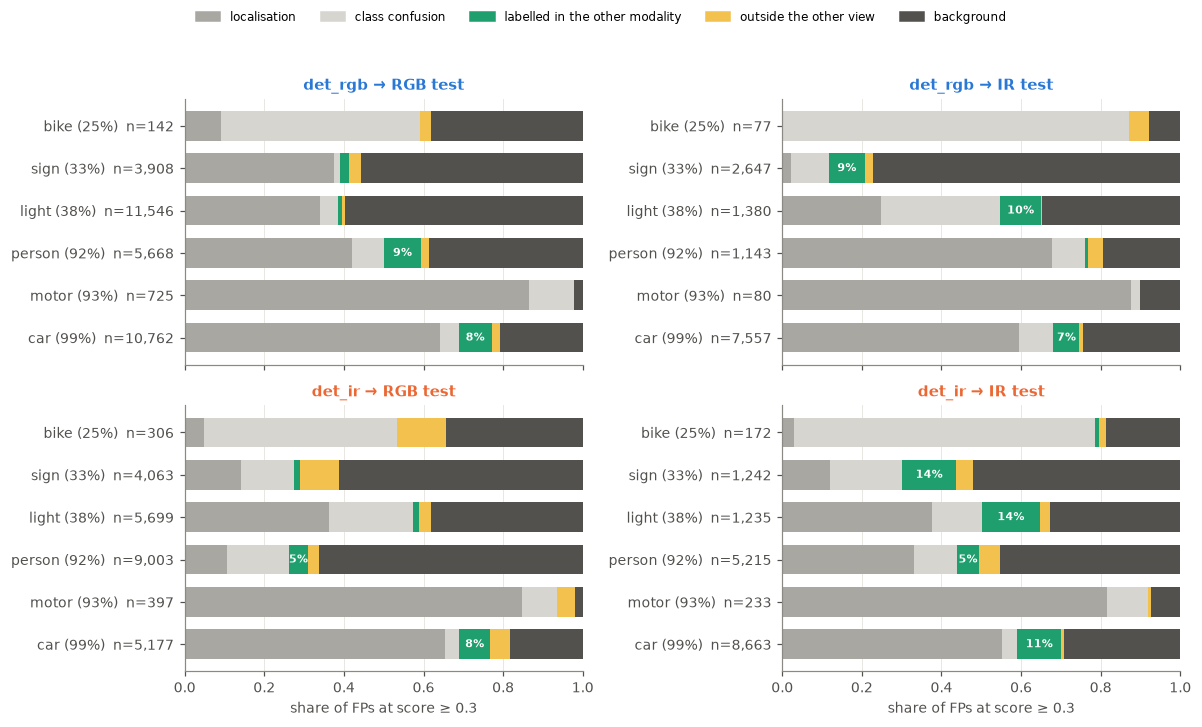

| class | cell | FPs @ 0.3 | localisation | class confusion | labelled in the other modality | outside the other view | background | precision | precision without other-modality FPs | Δ |
|---|---|---|---|---|---|---|---|---|---|---|
| bike | det_rgb → RGB test | 142 | 9% | 50% | 0% | 3% | 38% | 0.101 | 0.101 | 0.000 |
| bike | det_rgb → IR test | 77 | 0% | 87% | 0% | 5% | 8% | 0.000 | 0.000 | 0.000 |
| bike | det_ir → RGB test | 306 | 5% | 48% | 0% | 12% | 34% | 0.058 | 0.058 | 0.000 |
| bike | det_ir → IR test | 172 | 3% | 76% | 1% | 2% | 19% | 0.000 | 0.000 | 0.000 |
| sign | det_rgb → RGB test | 3908 | 37% | 2% | 2% | 3% | 56% | 0.546 | 0.551 | 0.006 |
| sign | det_rgb → IR test | 2647 | 2% | 9% | 9% | 2% | 77% | 0.135 | 0.147 | 0.012 |
| sign | det_ir → RGB test | 4063 | 14% | 13% | 2% | 10% | 61% | 0.333 | 0.337 | 0.003 |
| sign | det_ir → IR test | 1242 | 12% | 18% | 14% | 4% | 52% | 0.424 | 0.461 | 0.036 |
| light | det_rgb → RGB test | 11546 | 34% | 4% | 1% | 1% | 60% | 0.235 | 0.237 | 0.002 |
| light | det_rgb → IR test | 1380 | 25% | 30% | 10% | 0% | 35% | 0.361 | 0.386 | 0.025 |
| light | det_ir → RGB test | 5699 | 36% | 21% | 1% | 3% | 38% | 0.303 | 0.305 | 0.003 |
| light | det_ir → IR test | 1235 | 38% | 13% | 14% | 3% | 33% | 0.525 | 0.564 | 0.039 |
| person | det_rgb → RGB test | 5668 | 42% | 8% | 9% | 2% | 39% | 0.492 | 0.516 | 0.025 |
| person | det_rgb → IR test | 1143 | 68% | 8% | 1% | 4% | 20% | 0.780 | 0.782 | 0.002 |
| person | det_ir → RGB test | 9003 | 11% | 15% | 5% | 3% | 66% | 0.219 | 0.227 | 0.009 |
| person | det_ir → IR test | 5215 | 33% | 11% | 5% | 5% | 45% | 0.623 | 0.635 | 0.013 |
| motor | det_rgb → RGB test | 725 | 87% | 11% | 0% | 0% | 2% | 0.668 | 0.668 | 0.000 |
| motor | det_rgb → IR test | 80 | 88% | 2% | 0% | 0% | 10% | 0.693 | 0.693 | 0.000 |
| motor | det_ir → RGB test | 397 | 85% | 9% | 0% | 5% | 2% | 0.757 | 0.757 | 0.000 |
| motor | det_ir → IR test | 233 | 82% | 10% | 0% | 1% | 7% | 0.658 | 0.658 | 0.000 |
| car | det_rgb → RGB test | 10762 | 64% | 5% | 8% | 2% | 21% | 0.623 | 0.643 | 0.020 |
| car | det_rgb → IR test | 7557 | 60% | 9% | 7% | 1% | 24% | 0.673 | 0.688 | 0.015 |
| car | det_ir → RGB test | 5177 | 66% | 3% | 8% | 5% | 18% | 0.702 | 0.718 | 0.017 |
| car | det_ir → IR test | 8663 | 55% | 4% | 11% | 1% | 29% | 0.714 | 0.737 | 0.023 |

In [5]:
FP_TYPES = ["localisation", "class confusion", "labelled in the other modality", "outside the other view", "background"]
FP_COLOR = dict(zip(FP_TYPES, ["#a8a7a2", "#d6d5d0", "#1f9e6e", "#f2c14e", "#52514e"]))


def rgb_norm(m, x, boxes, P):
    """COCO xywh px of record x (modality m) -> RGB-normalised xyxy."""
    c = ncent(boxes, x)
    return xyxy(c if m == "rgb" else to_rgb(P, c))


def fp_types(h, m, tau=TAU):
    """Type of every FP at score ≥ tau of cell (h, m), aligned with MATCH[h, m]; "" for non-FPs."""
    mt, _ = MATCH[h, m]
    types = np.full(len(mt["status"]), "", dtype=object)
    sel = np.flatnonzero((mt["status"] == "FP") & (mt["score"] >= tau))
    by_img = defaultdict(list)
    for i in sel:
        by_img[int(mt["image_id"][i])].append(i)
    grow = np.array([-BOX_PAD, -BOX_PAD, BOX_PAD, BOX_PAD])
    for img, idx in by_img.items():
        r, t, P = FRAME[m, img]
        own, oth = (r, t) if m == "rgb" else (t, r)
        idx = np.array(idx)
        db = np.asarray(mt["bbox"][idx], dtype=float)
        lab = mt["label"][idx]
        # Own modality, native px.
        d_xyxy = np.c_[db[:, :2], db[:, :2] + db[:, 2:]]
        g = np.asarray(own.boxes, dtype=float).reshape(-1, 4)
        g_xyxy = np.c_[g[:, :2], g[:, :2] + g[:, 2:]]
        ov = iou(d_xyxy, g_xyxy)
        same = ov * (lab[:, None] == own.labels[None, :])
        diff = ov * (lab[:, None] != own.labels[None, :])
        # Other modality, RGB-normalised, both grown as in §0.
        dn = rgb_norm(m, own, db, P)
        on = rgb_norm(OTHER[m], oth, oth.boxes, P)
        ovo = iou(dn + grow, on + grow) * (lab[:, None] == oth.labels[None, :])
        shared = shared_view(P)
        out = (dn[:, :2] < shared[:2] + BORDER).any(1) | (dn[:, 2:] > shared[2:] - BORDER).any(1)
        ty = np.full(len(idx), "background", dtype=object)
        ty[out] = "outside the other view"
        ty[ovo.max(1, initial=0) >= IOU_MATCH] = "labelled in the other modality"
        ty[diff.max(1, initial=0) >= 0.3] = "class confusion"
        ty[same.max(1, initial=0) >= 0.1] = "localisation"
        types[idx] = ty
    return types


FPT = {(h, m): fp_types(h, m) for h, m in CELLS}

# Composition of the FPs per class: one panel per cell, classes by label ratio.
fig, axes = plt.subplots(2, 2, figsize=(11, 6.6), sharex=True)
for ax, (h, m) in zip(axes.flat, CELLS):
    mt, _ = MATCH[h, m]
    left = np.zeros(len(BY_RATIO))
    n_fp = np.array([(FPT[h, m][mt["label"] == CLASS_NAMES.index(c)] != "").sum() for c in BY_RATIO])
    for ty in FP_TYPES:
        v = np.array([(FPT[h, m][mt["label"] == CLASS_NAMES.index(c)] == ty).sum() for c in BY_RATIO]) / np.maximum(n_fp, 1)
        ax.barh(np.arange(len(BY_RATIO)), v, left=left, color=FP_COLOR[ty], height=0.7, label=ty)
        for yi, (l, vi) in enumerate(zip(left, v)):
            if ty == "labelled in the other modality" and vi >= 0.04:
                ax.text(l + vi / 2, yi, f"{vi:.0%}", ha="center", va="center", fontsize=7.5, color="white",
                        fontweight="bold")
        left += v
    ax.set_yticks(np.arange(len(BY_RATIO)), [f"{c} ({RATIO[c]:.0%})  n={n:,}" for c, n in zip(BY_RATIO, n_fp)])
    ax.invert_yaxis()
    ax.set_xlim(0, 1)
    ax.grid(axis="y", visible=False)
    ax.set_title(cell_label(h, m), color=MOD_COLOR[HEAD_MOD[h]])
for ax in axes[1]:
    ax.set_xlabel(f"share of FPs at score ≥ {TAU}")
fig.legend(handles=[Patch(color=FP_COLOR[t], label=t) for t in FP_TYPES], loc="upper center", ncols=5, fontsize=8)
fig.suptitle("")
fig.tight_layout(rect=(0, 0, 1, 0.94))
plt.show()

rows = []
for c in BY_RATIO:
    for h, m in CELLS:
        mt, n_gt = MATCH[h, m]
        k = mt["label"] == CLASS_NAMES.index(c)
        cnt = Counter(FPT[h, m][k & (FPT[h, m] != "")])
        n_fp = sum(cnt.values())
        p, _, tp, fp = prec_rec(mt, n_gt, c)
        pc = prec_rec(mt, n_gt, c, drop=FPT[h, m] == "labelled in the other modality")[0]
        rows.append([c, cell_label(h, m), n_fp, *[f"{cnt[t] / n_fp:.0%}" if n_fp else "–" for t in FP_TYPES], p, pc,
                     pc - p])
table(["class", "cell", f"FPs @ {TAU}", *FP_TYPES, "precision", "precision without other-modality FPs", "Δ"], rows)

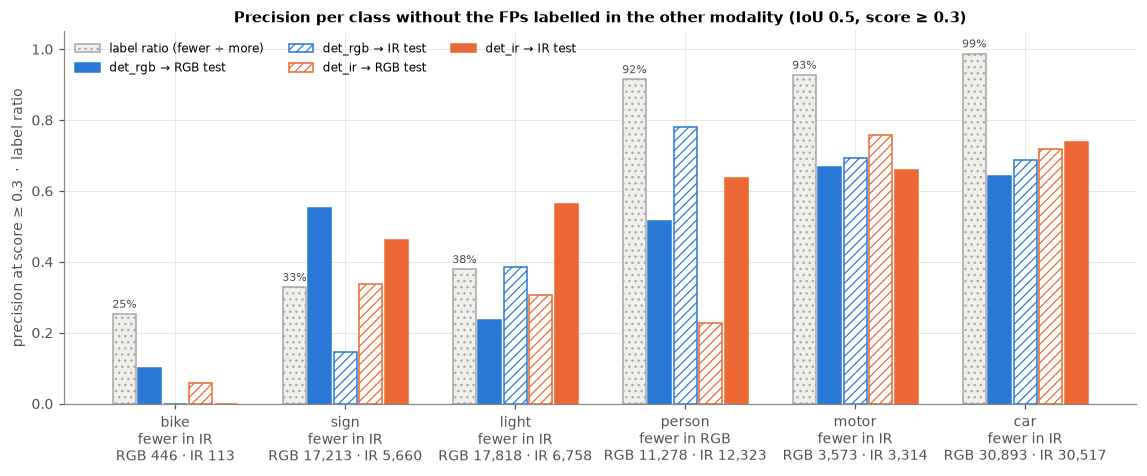

In [6]:
precision_plot(drop={k: v == "labelled in the other modality" for k, v in FPT.items()},
               title=f"Precision per class without the FPs labelled in the other modality (IoU 0.5, score ≥ {TAU})")
plt.show()

**Reading.**
- **FPs on objects labelled only in the other modality are a small share everywhere: 0–14 %.** Not counting them
  raises precision by at most **0.039** (`det_ir` on IR lights, 0.525 → 0.564), and by 0.012 for `det_rgb` on IR
  signs (0.135 → 0.147), the case §1 flagged. 77 % of those sign FPs are `background`: no sign in either GT.
- **The largest shares are in the in-domain IR cell**: 14 % of `det_ir`'s sign FPs and 14 % of its light FPs on IR
  are signs and lights that RGB labelled and IR skipped. `det_ir` finds a few of the objects the IR annotators left
  out, but they are 170–175 detections per class.
- **Car FPs are 7–11 % "labelled in the other modality" in all four cells**, so both GTs miss a few cars the other has
  (distant cars by day in RGB, dark cars at night in IR; `test_set_quality.ipynb` §2c). The effect is symmetric and
  small.
- **Most FPs are not labelling problems.** Car and motor FPs are mostly `localisation` (55–66 % and 82–88 %: a
  duplicate or a loose box on a labelled object); bike FPs are mostly `class confusion` (48–87 %); sign and light FPs
  are mostly `background` or `localisation`.
- The second figure (precision without those FPs) is nearly identical to §1's.

### 2.1 The other direction: do the heads detect the objects only one modality labels?

§2 starts from the detections. This starts from the objects. Take the GT boxes that only one modality labels (§0
status `missing` / `empty frame`) and, as a reference, the boxes labelled in both (`matched`). For each, check whether
a head puts a **same-class detection with score ≥ `TAU`** on it, in **both images** of the pair: in the labelling
modality's own frame, and at the mapped position in the other frame (padded IoU ≥ 0.3 in RGB-normalised coordinates,
the §0 rule, used for both frames so that the two numbers are comparable). `border` boxes are left out.

If an object labelled only in RGB were plainly visible in IR, a head would find it in the IR image about as often as
in the RGB image, and the IR GT would then charge those detections as FPs. If the head finds it in RGB but not in IR,
the IR annotator and the detector agree: the object does not show in thermal.

In [7]:
def dets_by_image(h, m, tau=TAU):
    """image_id -> (labels [N], RGB-normalised xyxy [N, 4]) of cell (h, m) at score ≥ tau."""
    raw = defaultdict(list)
    for d in DETS[h, m]:
        if d["score"] >= tau:
            raw[d["image_id"]].append(d)
    out = {}
    for img, ds in raw.items():
        r, t, P = FRAME[m, img]
        x = r if m == "rgb" else t
        out[img] = (np.array([CATEGORY_ID_TO_LABEL[d["category_id"]] for d in ds]),
                    rgb_norm(m, x, [d["bbox"] for d in ds], P))
    return out


DBI = {(h, m): dets_by_image(h, m) for h, m in CELLS}
GROW = np.array([-BOX_PAD, -BOX_PAD, BOX_PAD, BOX_PAD])
OBJ_SETS = [("rgb", ONLY_HERE, "RGB only"), ("thermal", ONLY_HERE, "IR only"), ("rgb", ("matched",), "both")]
hits = defaultdict(lambda: np.zeros(2, dtype=int))  # (set, class, head, image modality) -> [hit, total]
for o, statuses, name in OBJ_SETS:
    for x in SPLIT[o]:
        st = STATUS[o, x.image_id]
        keep = np.isin(st, statuses)
        if not keep.any():
            continue
        r, t, P = FRAME[o, x.image_id]
        gb = rgb_norm(o, x, x.boxes[keep], P) + GROW
        gl = x.labels[keep]
        for h in HEADS:
            for m in MODS:
                img = (r if m == "rgb" else t).image_id
                dl, db = DBI[h, m].get(img, (np.zeros(0, int), np.zeros((0, 4))))
                ov = iou(gb, db + GROW) * (gl[:, None] == dl[None, :])
                hit = ov.max(1, initial=0) >= IOU_MATCH
                for lab, hi in zip(gl, hit):
                    hits[name, CLASS_NAMES[lab], h, m] += [int(hi), 1]

rows = []
for c in BY_RATIO:
    for _, _, name in OBJ_SETS:
        n = hits[name, c, "det_rgb", "rgb"][1]
        if n < 20:
            continue
        rows.append([c, name, n, *[f"{hits[name, c, h, m][0] / n:.0%}" for h, m in CELLS]])
table(["class", "labelled in", "objects", *[f"found by {h} in the {MOD_LABEL[m]} image" for h, m in CELLS]], rows)
display(Markdown(f"Classes × sets with fewer than 20 objects are left out. Score ≥ {TAU}; `both` = labelled in both "
                 "modalities (the RGB box of each matched pair)."))

| class | labelled in | objects | found by det_rgb in the RGB image | found by det_rgb in the IR image | found by det_ir in the RGB image | found by det_ir in the IR image |
|---|---|---|---|---|---|---|
| bike | RGB only | 297 | 4% | 1% | 7% | 4% |
| bike | both | 110 | 13% | 0% | 12% | 5% |
| sign | RGB only | 11488 | 31% | 2% | 13% | 2% |
| sign | IR only | 1020 | 7% | 3% | 3% | 2% |
| sign | both | 4458 | 54% | 10% | 28% | 24% |
| light | RGB only | 10739 | 52% | 2% | 22% | 6% |
| light | IR only | 220 | 15% | 0% | 15% | 2% |
| light | both | 6456 | 83% | 19% | 64% | 34% |
| person | RGB only | 581 | 32% | 4% | 17% | 37% |
| person | IR only | 1626 | 24% | 18% | 15% | 70% |
| person | both | 10320 | 69% | 45% | 37% | 86% |
| motor | RGB only | 333 | 38% | 10% | 28% | 16% |
| motor | IR only | 137 | 2% | 0% | 4% | 1% |
| motor | both | 3145 | 60% | 11% | 51% | 24% |
| car | RGB only | 3185 | 65% | 31% | 25% | 40% |
| car | IR only | 3378 | 35% | 66% | 24% | 80% |
| car | both | 26321 | 82% | 77% | 61% | 90% |

Classes × sets with fewer than 20 objects are left out. Score ≥ 0.3; `both` = labelled in both modalities (the RGB box of each matched pair).

**Reading.**
- **Objects only RGB labels are, for the detectors too, invisible in IR.** Of the 11,488 RGB-only signs, `det_rgb`
  finds 31 % in the RGB image and **2 %** in the IR image; of the 10,739 RGB-only lights, 52 % and **2 %**. `det_ir`,
  which was trained on thermal, also finds only 2 % and 6 % of them in IR, while it finds 13 % and 22 % in RGB. The IR
  annotators skipped what thermal does not show, and the heads, trained on either modality, agree. So these objects
  produce almost no IR false positives, which is why §2 found so few.
- **Objects only IR labels (mostly night cars and distant persons) are the mirror case.** `det_rgb` finds 66 % of
  IR-only cars in the IR image but 35 % in the RGB image; `det_ir` 80 % and 24 %. In RGB they are dark or blinded by
  glare, so the RGB GT not labelling them costs little.
- **One partial exception: persons only RGB labels** (581). `det_ir` finds 37 % of them in IR, more than in RGB
  (17 %). These are persons the IR annotators missed though thermal shows them; at most ≈ 215 detections, ≈ 5 % of
  `det_ir`'s IR person FPs (§2).
- **Even signs and lights labelled in both modalities are much harder in IR** (`det_rgb` 54 % → 10 % of signs and
  83 % → 19 % of lights). The low cross-modal AP of these classes in F15 comes from detection in the thermal image, not
  from the GT.

## 3. The 2×2 re-scored with the other modality's labels as ignore regions

§2 counts FPs at one operating point. To see the effect on F15's metric, each test split's GT is extended with the
boxes that **only the other modality** labels (§0 status `missing` or `empty frame`), mapped into this frame, grown
by 1 % of the frame and added as **crowd (ignore) boxes of their class**. A detection on one of them is then neither
TP nor FP, exactly like a detection on a truck. Kept GT and existing ignore regions are unchanged, so a detection
matched to a real GT box stays a TP and **AP can only rise** (checked below). `border` boxes are not added: the other
camera may not see them.

This is an upper bound on the labelling effect, not a corrected ground truth: it forgives every detection on an
object the other modality labels, including objects this modality truly cannot show (the distant headlights of the
256 empty IR frames, `test_set_quality.ipynb` §2a). The full `COCOeval` runs on all 300 detections per frame, so it
takes a few minutes per cell; results are cached next to the transfer analysis.

RGB test: +6,383 ignore boxes from IR-only labels
IR test: +26,623 ignore boxes from RGB-only labels
loaded ../outputs/detection/transfer_analysis/dinov2_vitb14reg_448x560_l3-6-9-12_pca1152/label_mismatch.json
union-GT AP ≥ F15 AP for every cell and key


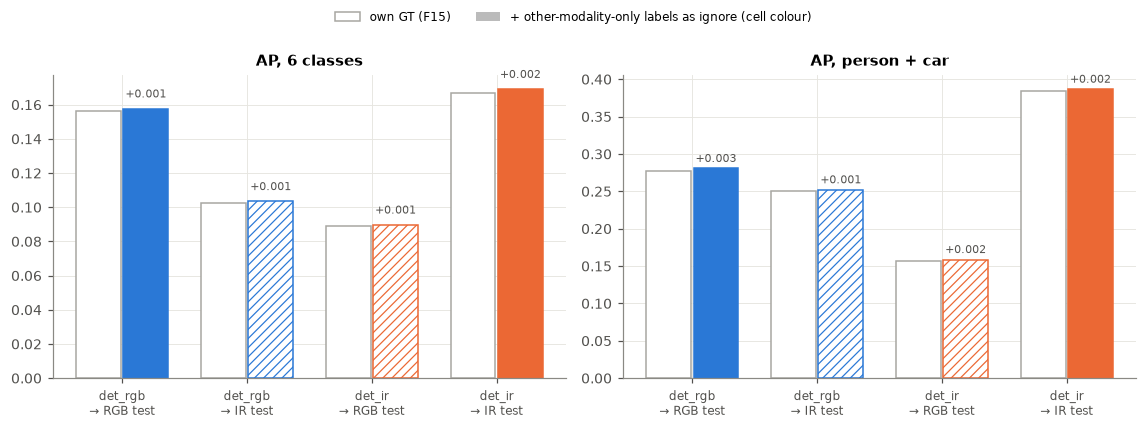

| cell | AP own | AP union | AP50 own | AP50 union | AP p+c own | AP p+c union | ratio AP own | ratio AP union | ratio p+c own | ratio p+c union |
|---|---|---|---|---|---|---|---|---|---|---|
| det_rgb → RGB test | 0.157 | 0.158 | 0.331 | 0.334 | 0.278 | 0.281 | – | – | – | – |
| det_rgb → IR test | 0.102 | 0.103 | 0.205 | 0.208 | 0.251 | 0.252 | 0.615 | 0.612 | 0.653 | 0.652 |
| det_ir → RGB test | 0.089 | 0.090 | 0.201 | 0.203 | 0.157 | 0.159 | 0.569 | 0.569 | 0.566 | 0.566 |
| det_ir → IR test | 0.167 | 0.169 | 0.334 | 0.340 | 0.385 | 0.387 | – | – | – | – |

ratio = ÷ the in-domain head on the same split (F15's `transfer_ratio`).

| class | label ratio | det_rgb → RGB test | det_rgb → IR test | det_ir → RGB test | det_ir → IR test |
|---|---|---|---|---|---|
| bike | 0.25 | 0.012 → 0.012 | 0.000 → 0.000 | 0.003 → 0.003 | 0.000 → 0.000 |
| sign | 0.33 | 0.136 → 0.137 | 0.023 → 0.024 | 0.042 → 0.042 | 0.070 → 0.072 |
| light | 0.38 | 0.044 → 0.044 | 0.039 → 0.040 | 0.024 → 0.024 | 0.081 → 0.085 |
| person | 0.92 | 0.215 → 0.217 | 0.202 → 0.202 | 0.077 → 0.078 | 0.359 → 0.360 |
| motor | 0.93 | 0.191 → 0.192 | 0.050 → 0.052 | 0.151 → 0.151 | 0.080 → 0.084 |
| car | 0.99 | 0.340 → 0.344 | 0.300 → 0.302 | 0.237 → 0.240 | 0.410 → 0.413 |

In [8]:
def union_gt(m):
    """GT of modality m plus the other modality's 'only there' boxes as per-class crowd boxes in m's pixels."""
    gt = copy.deepcopy(GT_OWN[m])
    o = OTHER[m]
    next_id = max(a["id"] for a in gt["annotations"]) + 1
    for x in SPLIT[o]:
        r, t, P = FRAME[o, x.image_id]
        keep = np.isin(STATUS[o, x.image_id], ONLY_HERE)
        if not keep.any():
            continue
        target = t if m == "thermal" else r
        c = ncent(x.boxes[keep], x)
        if o == "thermal":  # thermal -> RGB normalised
            c = to_rgb(P, c)
        else:  # RGB normalised -> thermal normalised (inverse of to_rgb)
            c = np.c_[(c[:, 0] - P[1]) / P[0], (c[:, 1] - P[3]) / P[2], c[:, 2] / P[0], c[:, 3] / P[2]]
        b = xyxy(c) + np.array([-BOX_PAD, -BOX_PAD, BOX_PAD, BOX_PAD])
        b = np.clip(b, 0, 1) * np.array([target.width, target.height] * 2)
        for (x0, y0, x1, y1), lab in zip(b, x.labels[keep]):
            if x1 <= x0 or y1 <= y0:
                continue
            gt["annotations"].append({
                "id": next_id, "image_id": int(target.image_id), "category_id": LABEL_TO_CATEGORY_ID[int(lab)],
                "bbox": [float(x0), float(y0), float(x1 - x0), float(y1 - y0)],
                "area": normalised_area(x1 - x0, y1 - y0, target.width, target.height), "iscrowd": 1})
            next_id += 1
    return gt


GT_UNION = {m: union_gt(m) for m in MODS}
for m in MODS:
    n_add = len(GT_UNION[m]["annotations"]) - len(GT_OWN[m]["annotations"])
    print(f"{MOD_LABEL[m]} test: +{n_add:,} ignore boxes from {MOD_LABEL[OTHER[m]]}-only labels")


def full_eval(job):
    """(head, modality) -> AP / AP50 / per class / person + car on the union GT, F8's coco_map settings."""
    h, m = job
    with contextlib.redirect_stdout(io.StringIO()):
        coco_gt = COCO()
        coco_gt.dataset = GT_UNION[m]
        coco_gt.createIndex()
        E = COCOeval(coco_gt, coco_gt.loadRes(DETS[h, m]), iouType="bbox")
        E.evaluate()
        E.accumulate()
    p = E.eval["precision"][:, :, :, 0, -1]  # [T, R, K] at area "all", maxDets 100
    mv = lambda v: float(v[v > -1].mean()) if (v > -1).any() else math.nan  # noqa: E731
    r = {"AP": mv(p), "AP50": mv(p[0])}
    for k, c in enumerate(CLASS_NAMES):
        kk = E.params.catIds.index(LABEL_TO_CATEGORY_ID[k])
        r[f"AP_{c}"], r[f"AP50_{c}"] = mv(p[:, :, kk]), mv(p[0, :, kk])
    for key in ["AP", "AP50"]:
        r[f"{key}_person_car"] = (r[f"{key}_person"] + r[f"{key}_car"]) / 2
    return job, r


cache_key = hashlib.sha256(json.dumps({
    "version": 1, "pad": BOX_PAD, "iou": IOU_MATCH, "border": BORDER, "map": {p: list(MAP[p]) for p in ORDER},
    "n_union": {m: len(GT_UNION[m]["annotations"]) for m in MODS},
    "sha256": {f"{h}/{m}": TRANSFER["detections"][h][m]["sha256"] for h, m in CELLS},
}, sort_keys=True).encode()).hexdigest()
CACHE = OUT / "detection/transfer_analysis" / TRANSFER["encoder"]["encoder_tag"] / "label_mismatch.json"
if CACHE.is_file() and json.loads(CACHE.read_text())["key"] == cache_key:
    cached = json.loads(CACHE.read_text())
    print(f"loaded {CACHE}")
else:
    with get_context("fork").Pool(2, maxtasksperchild=1) as pool:  # ≈ 4 GB per worker
        results = pool.map(full_eval, CELLS, chunksize=1)
    cached = {"key": cache_key, "created_with": "notebooks/phase2_flir_v2_detection/detector_label_mismatch.ipynb",
              "results": [{"cell": list(c), "metrics": r} for c, r in results]}
    CACHE.parent.mkdir(parents=True, exist_ok=True)
    CACHE.write_text(json.dumps(cached))
    print(f"wrote {CACHE}")
UNION = {tuple(e["cell"]): e["metrics"] for e in cached["results"]}


def own(h, m, key):
    """F15's metrics (own GT), from transfer.json; person + car as F15 computes it."""
    return TRANSFER["cells"][h][m][key]


for h, m in CELLS:  # adding crowd boxes can only turn FPs into ignored detections
    for key, v in UNION[h, m].items():
        ref = own(h, m, key)
        assert math.isnan(ref) or v >= ref - 1e-12, (h, m, key, v, ref)
print("union-GT AP ≥ F15 AP for every cell and key")

IN_DOMAIN = {m: h for h, m in HEAD_MOD.items()}
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.9))
for ax, key, title in zip(axes, ["AP", "AP_person_car"], ["AP, 6 classes", "AP, person + car"]):
    x = np.arange(len(CELLS))
    ax.bar(x - 0.19, [own(h, m, key) for h, m in CELLS], 0.36, color="white", edgecolor=REF, linewidth=1.0,
           label="own GT (F15)")
    for xi, (h, m) in zip(x, CELLS):
        ax.bar(xi + 0.19, UNION[h, m][key], 0.36, **cell_style(h, m))
        ax.text(xi + 0.19, UNION[h, m][key] + 0.005, f"+{UNION[h, m][key] - own(h, m, key):.3f}", ha="center",
                va="bottom", fontsize=7.5, color=MUTED)
    ax.set_xticks(x, [cell_label(h, m).replace(" → ", "\n→ ") for h, m in CELLS], fontsize=8)
    ax.set_title(title)
    ax.set_ylim(0, None)
fig.legend(handles=[Patch(facecolor="white", edgecolor=REF, label="own GT (F15)"),
                    Patch(facecolor="#bbb", label="+ other-modality-only labels as ignore (cell colour)")],
           loc="upper center", ncols=2, fontsize=8)
fig.tight_layout(rect=(0, 0, 1, 0.92))
plt.show()

rows = []
for h, m in CELLS:
    row = [cell_label(h, m)]
    for key in ["AP", "AP50", "AP_person_car"]:
        row += [own(h, m, key), UNION[h, m][key]]
    if HEAD_MOD[h] != m:
        g = IN_DOMAIN[m]
        row += [own(h, m, "AP") / own(g, m, "AP"), UNION[h, m]["AP"] / UNION[g, m]["AP"],
                own(h, m, "AP_person_car") / own(g, m, "AP_person_car"),
                UNION[h, m]["AP_person_car"] / UNION[g, m]["AP_person_car"]]
    else:
        row += [None] * 4
    rows.append(row)
table(["cell", "AP own", "AP union", "AP50 own", "AP50 union", "AP p+c own", "AP p+c union",
       "ratio AP own", "ratio AP union", "ratio p+c own", "ratio p+c union"], rows)
display(Markdown("ratio = ÷ the in-domain head on the same split (F15's `transfer_ratio`)."))

rows = [[c, f"{RATIO[c]:.2f}", *[f"{own(h, m, f'AP_{c}'):.3f} → {UNION[h, m][f'AP_{c}']:.3f}" for h, m in CELLS]]
        for c in BY_RATIO]
table(["class", "label ratio", *[cell_label(h, m) for h, m in CELLS]], rows)

**Reading.**
- **Adding 26,623 RGB-only boxes to IR test and 6,383 IR-only boxes to RGB test as ignore regions changes AP by at
  most 0.003** (AP50 by at most 0.006, `det_ir` on IR 0.334 → 0.340). Per class the largest change is +0.004 (`det_ir`
  on IR lights and motorcycles, `det_rgb` on RGB cars).
- **F15's transfer ratios do not move:** 0.615 → 0.612 for `det_rgb` on IR and 0.569 → 0.569 for `det_ir` on RGB (person
  + car: 0.653 → 0.652, 0.566 → 0.566). The cross-modal gap at the detector level is not a labelling artefact.
- This is an upper bound on the labelling effect (it forgives every detection on those objects), and it is still
  negligible, because §2.1 shows the heads rarely fire on them.

## Caveats

- **Preliminary until F6.** No bootstrap CIs; 8 video pairs. Bike and motor sit almost entirely in the dawn video.
- **One operating point for §1–§2.1** (score ≥ 0.3, IoU 0.5). §1's table gives 0.2 and 0.5; §3 is threshold-free (AP).
- **The registration is per video pair** (similarity, median residual 2–8 RGB px, `test_set_quality.ipynb` §2b); with
  parallax and box jitter, very small objects can fail the padded IoU ≥ 0.3 and be typed `background` instead of
  `labelled in the other modality`. The matched-share grid of `test_set_quality.ipynb` §2c bounds this: from 1 % to 2 %
  padding, the person + car matched share rises by only 1.7 points.
- **`background` includes objects that both annotators skipped**; this notebook cannot separate those from true FPs.
- **The FP types are ordered** (localisation before cross-modal), so a loose box on an object both modalities label
  counts as `localisation`, never as cross-modal.
- Code for the registration and the GT status is copied from `test_set_quality.ipynb`; a change there must be copied
  here by hand.